In [5]:
import pandas as pd

In [7]:
data =pd.read_csv('/Users/manzu/Downloads/1학년2학기_데이터사이선스이해/ch5/wisc_bc_data.csv', sep=",")

In [8]:
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,points_worst,symmetry_worst,dimension_worst
0,87139402,B,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,...,13.50,15.64,86.97,549.1,0.1385,0.1266,0.12420,0.09391,0.2827,0.06771
1,8910251,B,10.60,18.95,69.28,346.4,0.09688,0.11470,0.06387,0.02642,...,11.88,22.94,78.28,424.8,0.1213,0.2515,0.19160,0.07926,0.2940,0.07587
2,905520,B,11.04,16.83,70.92,373.2,0.10770,0.07804,0.03046,0.02480,...,12.41,26.44,79.93,471.4,0.1369,0.1482,0.10670,0.07431,0.2998,0.07881
3,868871,B,11.28,13.39,73.00,384.8,0.11640,0.11360,0.04635,0.04796,...,11.92,15.77,76.53,434.0,0.1367,0.1822,0.08669,0.08611,0.2102,0.06784
4,9012568,B,15.19,13.21,97.65,711.8,0.07963,0.06934,0.03393,0.02657,...,16.20,15.73,104.50,819.1,0.1126,0.1737,0.13620,0.08178,0.2487,0.06766


In [9]:
len(data)

569

In [10]:
data.shape # number of features = 30

(569, 32)

In [11]:
res = data['diagnosis'].value_counts() # unique value count
print(res)


diagnosis
B    357
M    212
Name: count, dtype: int64


In [12]:
data.groupby(['diagnosis'])['radius_mean'].mean()

diagnosis
B    12.146524
M    17.462830
Name: radius_mean, dtype: float64

<Axes: title={'center': 'smoothness_mean'}, xlabel='diagnosis'>

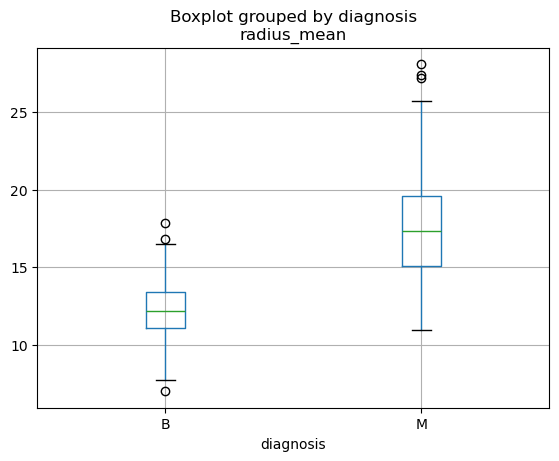

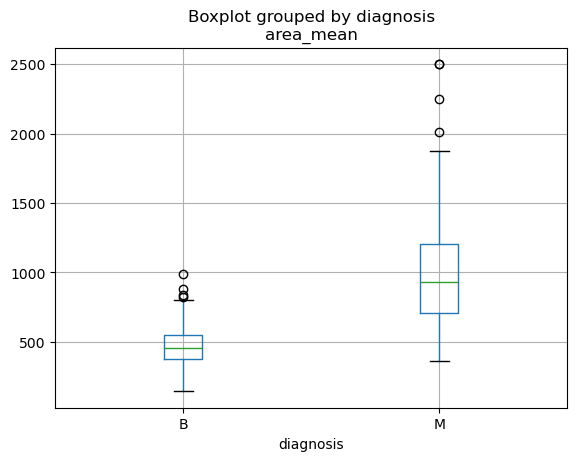

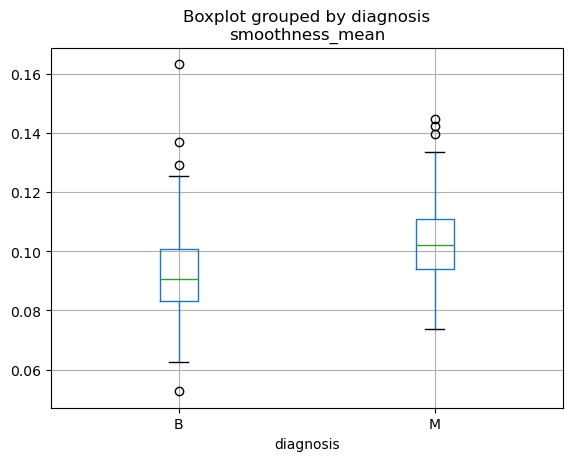

In [13]:
data.boxplot(column=['radius_mean'],by='diagnosis')
data.boxplot(column=['area_mean'],by='diagnosis')
data.boxplot(column=['smoothness_mean'],by='diagnosis')

In [14]:
# StandardScaler
from sklearn.preprocessing import scale, minmax_scale
from sklearn import neighbors, datasets
import numpy as np

X = data.iloc[:,2:].to_numpy()
Z = minmax_scale(X)

In [15]:
Z

array([[0.25268588, 0.0906324 , 0.24227766, ..., 0.32271478, 0.24876799,
        0.08310376],
       [0.17128118, 0.31247886, 0.17614539, ..., 0.27237113, 0.27104278,
        0.136626  ],
       [0.19210564, 0.24078458, 0.18747841, ..., 0.25536082, 0.28247585,
        0.15590975],
       ...,
       [0.3927777 , 0.42948935, 0.38096883, ..., 0.42130584, 0.31736645,
        0.27994228],
       [0.35728146, 0.14440311, 0.34600235, ..., 0.36735395, 0.20520402,
        0.15125279],
       [0.68100715, 0.18227934, 0.67383042, ..., 0.67560137, 0.22964715,
        0.20739866]], shape=(569, 30))

In [16]:
Z.shape

(569, 30)

* taget 값 생성 t = f(Z) 형태로 전환

In [17]:
data['target'] = data['diagnosis'].map({'B': 0, 'M': 1})
y = np.array(data['target'])
y


array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0,
       1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1,

* Train / Test Set 분리(Test Set 크기 30%)



In [18]:
from sklearn.model_selection import train_test_split
Z_train, Z_test, y_train, y_test = train_test_split(Z, y, test_size=0.3, random_state=2)

In [19]:
Z_train.shape, Z_test.shape

((398, 30), (171, 30))

* 3NN 모형을 만들고 모형의 정확도 측정

In [20]:
knn = neighbors.KNeighborsClassifier(n_neighbors=3)
knn.fit(Z_train, y_train) # 학습한다
pred = knn.predict(Z_test) # 결과를 0, 1
pred_prob = knn.predict_proba(Z_test) # 결과를 확률로 출력

In [21]:
pred


array([0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0])

In [22]:
from sklearn import metrics
print(metrics.confusion_matrix(y_test, pred))

[[98  2]
 [ 5 66]]


In [23]:
pred_prob

array([[1.        , 0.        ],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [1.        , 0.        ],
       [0.33333333, 0.66666667],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [0.66666667, 0.33333333],
       [0.33333333, 0.66666667],
       [1.        , 0.        ],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [1.        , 0.        ],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [0.        , 1.        ],
       [0.33333333, 0.66666667],
       [1.        , 0.        ],
       [1.        , 0.        ],
       [0.

In [24]:
pred_prob = pred_prob[:,1]

In [25]:
pred = np.where(pred_prob < 0.3, 0, 1)

In [26]:
pred


array([0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0])

In [27]:
y_test

array([0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0])

In [28]:
from sklearn import metrics
print(metrics.confusion_matrix(y_test, pred))

[[91  9]
 [ 3 68]]


H.W #4: 3NN 모형 이외에 더 좋은 모형은 없는가? <br>
(1) k 값을 입력받아 자동으로 confusion matrix를 출력하는 함수를 만들고 어떤 k가 최적인지 판단하시오.<br>
(2) 모든 변수를 사용하는 경우와 아닌 경우(일부 변수를 제거)의 결과를 비교 하시오.


In [30]:
from sklearn import neighbors, metrics
import pandas as pd
import matplotlib.pyplot as plt

feature_names = list(data.columns[2:32])   # Z의 열 이름 (30개)

def knn_cm(k, cols=None, show=True):
    """k와 (선택) 사용할 변수 이름 리스트를 받아 confusion matrix 출력"""
    idx = list(range(Z.shape[1])) if cols is None else [feature_names.index(c) for c in cols]
    model = neighbors.KNeighborsClassifier(n_neighbors=k).fit(Z_train[:, idx], y_train)
    pred = model.predict(Z_test[:, idx])
    cm = metrics.confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    acc, sens, spec = (tp+tn)/cm.sum(), tp/(tp+fn), tn/(tn+fp)
    if show:
        print(f"[k={k}, 변수 {len(idx)}개]")
        print(cm)
        print(f"정확도={acc:.4f}  민감도(악성 탐지)={sens:.4f}  특이도={spec:.4f}\n")
    return acc, sens, spec, fn

k = int(input("KNN의 k값을 입력하세요: "))
knn_cm(k)

[k=3, 변수 30개]
[[98  2]
 [ 5 66]]
정확도=0.9591  민감도(악성 탐지)=0.9296  특이도=0.9800



(np.float64(0.9590643274853801),
 np.float64(0.9295774647887324),
 np.float64(0.98),
 np.int64(5))

In [31]:
from sklearn import neighbors, metrics
import pandas as pd

feature_names = list(data.columns[2:32])

# 비교할 변수 조합
cases = {
    '전체 30개': feature_names,
    '29개': [c for c in feature_names if c != 'texture_se'],
    '26개': [c for c in feature_names if c not in ['texture_se', 'smoothness_se', 'symmetry_se', 'dimension_se']],
    '25개': [c for c in feature_names if c not in ['texture_se', 'smoothness_se', 'symmetry_se', 'dimension_se', 'compactness_se']],
    '평균 10개': [c for c in feature_names if c.endswith('_mean')],
    '최댓값 계열 10개': [c for c in feature_names if c.endswith('_worst')]
}

results = []

for name, cols in cases.items():
    idx = [feature_names.index(c) for c in cols]
    model = neighbors.KNeighborsClassifier(n_neighbors=3)
    model.fit(Z_train[:, idx], y_train)
    pred = model.predict(Z_test[:, idx])

    tn, fp, fn, tp = metrics.confusion_matrix(y_test, pred).ravel()
    acc = (tp + tn) / (tp + tn + fp + fn)
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)

    results.append([name, len(cols), acc, sens, spec, fn])

df = pd.DataFrame(results, columns=['사용 변수', '변수 개수', '정확도', '민감도', '특이도', 'FN'])
print(df.to_string(index=False))

     사용 변수  변수 개수      정확도      민감도  특이도  FN
    전체 30개     30 0.959064 0.929577 0.98   5
       29개     29 0.959064 0.929577 0.98   5
       26개     26 0.953216 0.929577 0.97   5
       25개     25 0.941520 0.929577 0.95   5
    평균 10개     10 0.918129 0.901408 0.93   7
최댓값 계열 10개     10 0.941520 0.915493 0.96   6
